# Level 1 - Task 3: K-Nearest Neighbors (KNN) Classifier
**Codveda ML Internship**

**Dataset:** Breast Cancer Wisconsin (built into scikit-learn). Goal: classify a tumor as **malignant (0)** or **benign (1)**.

**Steps:** 1) Load data  2) Split + scale  3) Train KNN  4) Evaluate (accuracy, confusion matrix, precision/recall)  5) Compare different K values

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score, classification_report)

## 1. Load the dataset

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print('Shape:', X.shape)
print('Classes:', dict(zip(data.target_names, [0, 1])))
print('\nClass counts:')
print(y.value_counts())
X.head()

Shape: (569, 30)
Classes: {np.str_('malignant'): 0, np.str_('benign'): 1}

Class counts:
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Train/test split and scaling
KNN is **distance-based**, so features must be on the same scale. The scaler is fit on training data only.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train:', X_train_s.shape, '| Test:', X_test_s.shape)

Train: (455, 30) | Test: (114, 30)


## 3. Train KNN (K = 5)

In [4]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.9561


## 4. Evaluation: confusion matrix, precision, recall

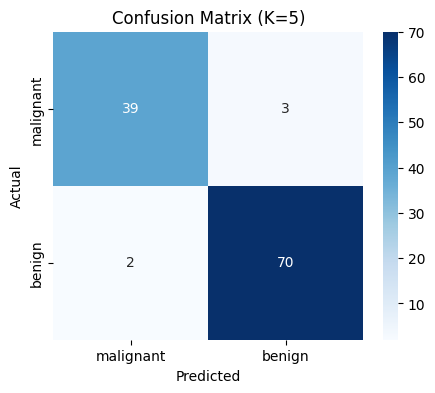

Precision: 0.9589
Recall   : 0.9722

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [5]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (K=5)')
plt.show()

print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))

## 5. Try different values of K and compare

In [6]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
rows = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    rows.append({'K': k,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p)})

results = pd.DataFrame(rows).round(4)
results

,K,Accuracy,Precision,Recall
0,1,0.9386,0.9577,0.9444
1,3,0.9825,0.9730,1.0000
2,5,0.9561,0.9589,0.9722
3,7,0.9737,0.9600,1.0000
4,9,0.9737,0.9600,1.0000
5,11,0.9737,0.9600,1.0000
6,15,0.9737,0.9600,1.0000
7,21,0.9649,0.9474,1.0000


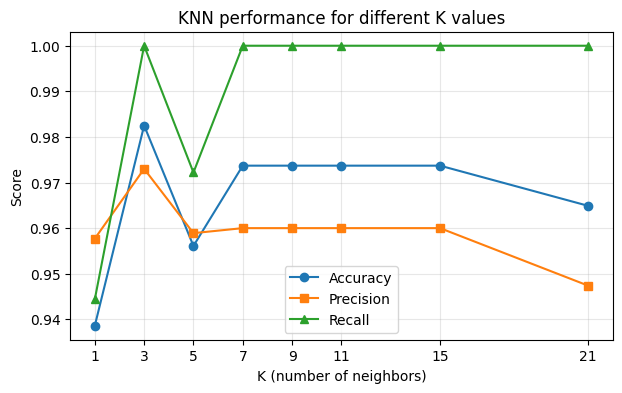

Best K by accuracy: 3 | Accuracy: 0.9825


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(results['K'], results['Accuracy'], marker='o', label='Accuracy')
plt.plot(results['K'], results['Precision'], marker='s', label='Precision')
plt.plot(results['K'], results['Recall'], marker='^', label='Recall')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Score')
plt.title('KNN performance for different K values')
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = results.loc[results['Accuracy'].idxmax()]
print('Best K by accuracy:', int(best['K']), '| Accuracy:', best['Accuracy'])

## Summary
- KNN with scaled features performs very well on the Breast Cancer dataset (accuracy around 95-97%).
- **Small K** (e.g. 1) follows noise in the data closely (can overfit); **large K** smooths the decision and can underfit.
- Medium values of K generally give the most stable results.
- Scaling is essential for KNN because it relies on distances between points.
- In medical problems **recall** matters a lot, since missing a real case is costly.